# Kam zmizí sluneční záření: bilance povrchů ze Sentinelu-2

[![Otevřít v Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/radiation_balance_cs.ipynb)

**OpenSkyLab · notebook k vizuálu** [Kam zmizí záření](https://openskylab.space/edu_viz_radiation_balance.html) · [English version](radiation_balance_en.ipynb)

Ve vizuálu se dopadající záření dělí na odražené, pohlcené a prošlé, ρ + α + τ = 1, a podle Kirchhoffova zákona platí ε = α. Tady odrazivost změříš na skutečných pixelech Sentinelu-2 (les, louka, pole, zástavba, voda a sníh), spočítáš, kolik záření povrchy pohltí za skutečného počasí, a odhadneš, jak se ohřejí.

**Cíl:** ze skutečné odrazivosti spočítat pohltivost a albedo povrchů, použít Kirchhoffův zákon na sníh a kovy a z energetické bilance s aktuálním počasím odhadnout rovnovážnou teplotu povrchu a navrhnout chladnou střechu.

**Data:** Sentinel-2 L2A (odrazivost na povrchu) z katalogu Earth Search na AWS: scéna `S2B_33UVR_20240721_0_L2A` (21. 7. 2024, okolí Roztok u Prahy) a `S2A_33UWS_20240308_0_L2A` (8. 3. 2024, Krkonoše se sněhem); třídy pokryvu ESA WorldCover 2021; hodinové počasí pro Prahu z Open-Meteo (posledních 92 dní). Stahuje se asi 15 MB.

**Úkoly:** šest. Odpovědi piš do buněk *Tvoje odpověď* pod úkoly. Řádky označené `# ◀ parametr` můžeš měnit a buňku spustit znovu (Shift + Enter).

**Čas:** asi 40 min. Potřebuješ Google účet (Colab); nic se neinstaluje do počítače. Buňky spouštěj popořadě shora dolů.

## 1. Příprava

In [1]:
%pip install -q rasterio

Note: you may need to restart the kernel to use updated packages.


In [2]:
import time, requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import rasterio
from rasterio.warp import reproject, Resampling
from pyproj import Transformer
from scipy.optimize import brentq

STAC = "https://earth-search.aws.element84.com/v1/collections/sentinel-2-l2a/items/"
WORLDCOVER = "https://esa-worldcover.s3.eu-central-1.amazonaws.com/v200/2021/map/ESA_WorldCover_10m_2021_v200_N48E012_Map.tif"
BANDS = ["coastal", "blue", "green", "red", "rededge1", "rededge2", "rededge3", "nir", "nir08", "swir16", "swir22"]

def read_on_grid(url, grid, resampling=Resampling.bilinear, dtype=np.float32):
    """Přečte rastr z cloudu a převzorkuje ho na mřížku grid = (transformace, crs, výška, šířka)."""
    tr, crs, ny, nx = grid
    out = np.zeros((ny, nx), dtype)
    with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR", GDAL_HTTP_MAX_RETRY=5, GDAL_HTTP_RETRY_DELAY=2):
        with rasterio.open("/vsicurl/" + url) as src:
            reproject(rasterio.band(src, 1), out, dst_transform=tr, dst_crs=crs, resampling=resampling)
    return out

def s2_window(item_id, lon, lat, half):
    """Odrazivost všech pásem Sentinelu-2 L2A ve čtverci kolem bodu (mřížka 10 m v UTM dlaždice)."""
    item = requests.get(STAC + item_id, timeout=60).json()
    epsg = item["properties"]["proj:epsg"] if "proj:epsg" in item["properties"] else int(item["properties"]["proj:code"].split(":")[1])
    x, y = Transformer.from_crs(4326, epsg, always_xy=True).transform(lon, lat)
    n = int(2 * half / 10)
    grid = (rasterio.transform.from_origin(x - half, y + half, 10, 10), f"EPSG:{epsg}", n, n)
    # od základní linie zpracování 04.00 (2022) mají DN posun +1000; Earth Search ho u novějších položek už odečetl
    p = item["properties"]
    offset = -1000 if float(p.get("s2:processing_baseline", "0")) >= 4 and not p.get("earthsearch:boa_offset_applied", False) else 0
    refl = {b: (read_on_grid(item["assets"][b]["href"], grid) + offset) / 10000 for b in BANDS}
    scl = read_on_grid(item["assets"]["scl"]["href"], grid, Resampling.nearest, np.uint8)
    wl = {b: item["assets"][b]["eo:bands"][0]["center_wavelength"] for b in BANDS}
    return refl, scl, wl, grid, item

def open_meteo(params, tries=6):
    """Dotaz na Open-Meteo; při chybě nebo vyčerpaném limitu to zkusí znovu."""
    for i in range(tries):
        try:
            r = requests.get("https://api.open-meteo.com/v1/forecast", params=params, timeout=60)
            if r.ok:
                return r.json()
            reason = r.json().get("reason", r.status_code)
        except requests.RequestException as e:
            reason = type(e).__name__
        print("Open-Meteo:", reason, "– zkusím znovu"); time.sleep(5 * (i + 1))
    raise RuntimeError("Open-Meteo neodpovídá, spusť buňku za chvíli znovu.")

## 2. Odrazivost skutečných povrchů

Načteme výřez 3 × 3 km kolem Roztok a pro každou třídu ESA WorldCover vezmeme medián odrazivosti čistých pixelů (bez mraků a stínů podle masky SCL). Přidáme sníh z Krkonoš.

In [3]:
refl, scl, wl, grid, item = s2_window("S2B_33UVR_20240721_0_L2A", 14.375, 50.145, 1500)
wc = read_on_grid(WORLDCOVER, grid, Resampling.nearest, np.uint8)
clear = np.isin(scl, [4, 5, 6])                     # 4 vegetace, 5 holý povrch, 6 voda
classes = {10: "les", 30: "louka", 40: "pole", 50: "zástavba", 80: "voda"}
spectra = {}
for code, name in classes.items():
    m = clear & (wc == code)
    spectra[name] = [float(np.median(refl[b][m])) for b in BANDS]
    print(f"{name:9s}: {m.sum():6d} pixelů")

snow_refl, snow_scl, *_ = s2_window("S2A_33UWS_20240308_0_L2A", 15.70, 50.735, 1500)
m = snow_scl == 11                                   # 11 = sníh a led
spectra["sníh"] = [float(np.median(snow_refl[b][m])) for b in BANDS]
print(f"sníh     : {m.sum():6d} pixelů")
R = pd.DataFrame(spectra, index=pd.Index([wl[b] for b in BANDS], name="λ (µm)"))
R.round(3)

les      :  39005 pixelů
louka    :  11347 pixelů
pole     :  27090 pixelů
zástavba :  11150 pixelů
voda     :   1058 pixelů


sníh     :  88400 pixelů


,les,louka,pole,zástavba,voda,sníh
λ (µm),,,,,,
0.443,0.031,0.040,0.048,0.060,0.028,0.714
0.490,0.032,0.048,0.066,0.074,0.028,0.751
0.560,0.049,0.075,0.086,0.091,0.030,0.780
0.665,0.029,0.063,0.118,0.099,0.022,0.810
0.704,0.079,0.123,0.141,0.131,0.024,0.833
0.740,0.248,0.263,0.170,0.213,0.015,0.814
0.783,0.313,0.307,0.186,0.244,0.017,0.784
0.842,0.322,0.318,0.189,0.237,0.012,0.794
0.865,0.338,0.335,0.207,0.256,0.012,0.761


## 3. Pohltivost: α = 1 − ρ − τ

Pixel je pro družici neprůhledný: co neodrazí zpět, pohltí porost, půda nebo voda pod ním. Pro celý pixel proto platí α = 1 − ρ. (U jednoho listu je τ v NIR asi stejně velké jako ρ; uvnitř porostu se ale prošlé záření dál odráží a pohlcuje.)

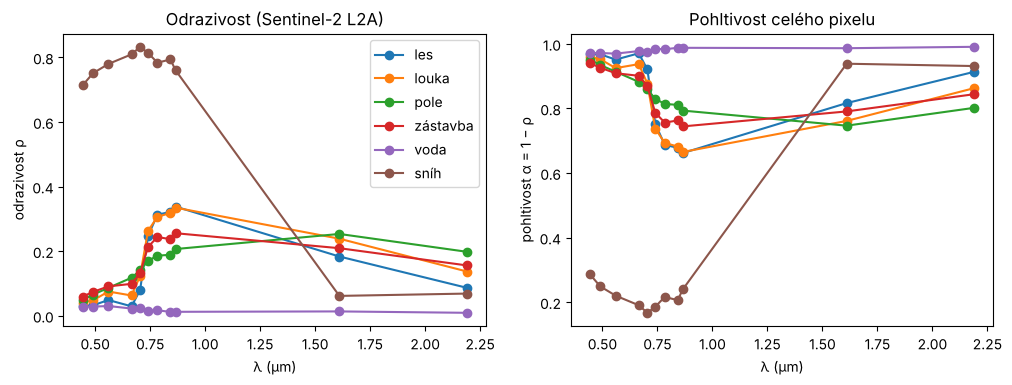

In [4]:
A = 1 - R
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharex=True)
R.plot(ax=ax[0], marker="o"); ax[0].set(ylabel="odrazivost ρ", title="Odrazivost (Sentinel-2 L2A)")
A.plot(ax=ax[1], marker="o", legend=False); ax[1].set(ylabel="pohltivost α = 1 − ρ", title="Pohltivost celého pixelu")
plt.show()

> **✏️ Úkol 1.** Kde les a louka pohlcují nejvíc a kde nejmíň? Proč je pro rostlinu výhodné NIR skoro nepohlcovat? Proč voda v NIR pohltí téměř vše, co do ní pronikne?

*Tvoje odpověď:* 

> **✏️ Úkol 2.** Sníh je ve viditelném světle bílý. Jakou má pohltivost v pásmu 1,6 µm (B11)? Podle Kirchhoffova zákona je při stejné vlnové délce ε = α. Termální pásmo (10 µm) Sentinel-2 nemá, ale trend od viditelného k SWIR naznačuje, jak se sníh chová dál. Proč je sníh v termální oblasti skoro černé těleso (ε ≈ 0,99) a co z toho plyne pro měření jeho teploty termokamerou?

*Tvoje odpověď:* 

## 4. Albedo: kolik slunečního záření povrch odrazí celkem

Albedo je odrazivost vážená spektrem Slunce. Liang (2001) ho pro pásma Landsatu odvodil jako lineární kombinaci; použijeme odpovídající pásma Sentinelu-2 (B2, B4, B8, B11, B12), takže výsledek je přibližný.

In [5]:
pick = lambda name, b: R[name].iloc[BANDS.index(b)]
albedo = pd.Series({name: 0.356 * pick(name, "blue") + 0.130 * pick(name, "red") + 0.373 * pick(name, "nir")
                         + 0.085 * pick(name, "swir16") + 0.072 * pick(name, "swir22") - 0.0018 for name in R.columns})
print(albedo.round(3).to_string())

les         0.155
louka       0.172
pole        0.143
zástavba    0.155
voda        0.017
sníh        0.677


## 5. Skutečné počasí a energetická bilance

Z Open-Meteo vezmeme nejslunečnější hodinu posledních 92 dní v Praze: globální záření S, teplotu vzduchu, rosný bod a vítr. Povrch v rovnováze (bez vypařování a vedení do země) splní

(1 − albedo) · S + ε · L↓ = ε · σ · T⁴ + h · (T − T_vzduch),

kde L↓ je dlouhovlnné záření oblohy (Brutsaert 1975, jasná obloha) a h = 5,7 + 3,8 · u je přestup tepla prouděním.

In [6]:
w = open_meteo({"latitude": 50.08, "longitude": 14.42, "past_days": 92, "forecast_days": 1, "wind_speed_unit": "ms",
                "hourly": "shortwave_radiation,temperature_2m,dew_point_2m,wind_speed_10m,cloud_cover", "timezone": "UTC"})
met = pd.DataFrame(w["hourly"]).set_index("time")
row = met.loc[met.shortwave_radiation.idxmax()]
print("nejslunečnější hodina:", row.name, "UTC"); print(row.to_string())

nejslunečnější hodina: 2026-08-24T11:00 UTC
shortwave_radiation    783.00
temperature_2m          18.80
dew_point_2m             9.20
wind_speed_10m           1.31
cloud_cover             33.00


In [7]:
SIGMA = 5.670374e-8
S, Ta, Td = row.shortwave_radiation, row.temperature_2m + 273.15, row.dew_point_2m
u = row.wind_speed_10m * 0.75          # ◀ parametr: vítr u povrchu (zhruba 3/4 větru v 10 m)
e_a = 6.112 * np.exp(17.62 * Td / (243.12 + Td))                  # tlak vodní páry (hPa), Magnusův vzorec
L_sky = 1.24 * (e_a / Ta) ** (1 / 7) * SIGMA * Ta**4               # Brutsaert, jasná obloha
h_c = 5.7 + 3.8 * u

def t_equilibrium(albedo, eps, S=S, Ta=Ta, L_sky=L_sky, h_c=h_c):
    f = lambda T: (1 - albedo) * S + eps * L_sky - eps * SIGMA * T**4 - h_c * (T - Ta)
    return brentq(f, 200, 400) - 273.15

eps_surface = {"les": 0.99, "louka": 0.98, "pole": 0.97, "zástavba": 0.93, "voda": 0.99, "sníh": 0.99}
tab = pd.DataFrame({"albedo": albedo, "ε": pd.Series(eps_surface)})
tab["pohlceno (W/m²)"] = (1 - tab.albedo) * S
tab["T rovnováha (°C)"] = [t_equilibrium(a, e) for a, e in zip(tab.albedo, tab["ε"])]
print(f"S = {S:.0f} W/m², vzduch {Ta - 273.15:.1f} °C, L↓ = {L_sky:.0f} W/m², h = {h_c:.1f} W·m⁻²·K⁻¹")
tab.round(2)

S = 783 W/m², vzduch 18.8 °C, L↓ = 322 W/m², h = 9.4 W·m⁻²·K⁻¹


,albedo,ε,pohlceno (W/m²),T rovnováha (°C)
les,0.16,0.99,661.42,54.31
louka,0.17,0.98,648.30,53.74
pole,0.14,0.97,670.95,55.25
zástavba,0.15,0.93,661.80,55.51
voda,0.02,0.99,769.35,60.46
sníh,0.68,0.99,252.79,29.50


> **✏️ Úkol 3.** Seřaď povrchy podle pohlceného záření a podle rovnovážné teploty. Skutečný osluněný les nebo louka bývají jen o pár stupňů teplejší než vzduch. Který člen bilance v modelu chybí? Jak se toho využívá při hledání vodního stresu porostu termokamerou z dronu? Proč model u vody selže úplně?

*Tvoje odpověď:* 

> **✏️ Úkol 4.** Změň `u` na 0,5 a pak na 6 m/s. Jak se změní rovnovážná teplota zástavby? Proč vítr teplotní rozdíly mezi povrchy zmenšuje?

*Tvoje odpověď:* 

## 6. Navrhni chladnou střechu

Měníme albedo a emisivitu střechy při stejném skutečném počasí. Lesklý kov odráží hodně slunce, ale v termální oblasti skoro nevyzařuje (ε ≈ 0,1); bílý nátěr odráží slunce a zároveň vyzařuje (ε ≈ 0,9).

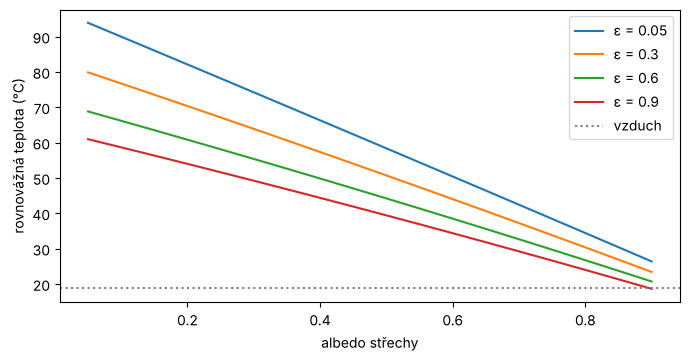

In [8]:
albedos = np.linspace(0.05, 0.9, 18)
fig, ax = plt.subplots(figsize=(8, 3.8))
for eps in (0.05, 0.3, 0.6, 0.9):          # ◀ parametr: emisivity střechy
    ax.plot(albedos, [t_equilibrium(a, eps) for a in albedos], label=f"ε = {eps}")
ax.axhline(Ta - 273.15, color="gray", ls=":", label="vzduch")
ax.set(xlabel="albedo střechy", ylabel="rovnovážná teplota (°C)"); ax.legend(); plt.show()

> **✏️ Úkol 5.** Jakou teplotu by měla střecha s albedem zástavby z tvého výřezu a jakou bílá střecha (albedo 0,8, ε 0,9)? Proč je lesklý plech s albedem 0,6 (ε 0,05) o tolik teplejší než nátěr se stejným albedem a emisivitou 0,9? Jaké vlastnosti má mít ideální nátěr v pásmu 0,3–2,5 µm a jaké v 8–13 µm?

*Tvoje odpověď:* 

> **✏️ Úkol 6.** Vyber z tabulky `met` jinou hodinu, třeba nejteplejší, a vlož ji místo `row` (např. `row = met.loc[met.temperature_2m.idxmax()]` pro nejteplejší hodinu). Jak se změní pořadí a teploty povrchů? Model dává sněhu teplotu nad 0 °C: proč to ve skutečnosti nejde a na co se přebytek energie spotřebuje? Proč na jaře sníh na slunci přesto neroztaje hned, i když S je vysoké?

*Tvoje odpověď:* 

---
### Zdroje dat a literatura

- Copernicus Sentinel-2 data 2024, ESA, zpracováno ESA (L2A, Sen2Cor); COG kopie v registru AWS Open Data (`sentinel-cogs`), katalog Earth Search (Element 84). Volné užití s uvedením zdroje podle [Legal notice on the use of Copernicus Sentinel Data](https://sentinels.copernicus.eu/documents/247904/690755/Sentinel_Data_Legal_Notice).
- Zanaga, D. a kol. (2022). *ESA WorldCover 10 m 2021 v200*. Zenodo. https://doi.org/10.5281/zenodo.7254221 (CC BY 4.0).
- Počasí: Open-Meteo.com, model ICON/ECMWF podle dostupnosti (CC BY 4.0). https://open-meteo.com
- Albedo z úzkých pásem: Liang, S. (2001). Narrowband to broadband conversions of land surface albedo I: Algorithms. *Remote Sensing of Environment* 76, 213–238. https://doi.org/10.1016/S0034-4257(00)00205-4
- Dlouhovlnné záření jasné oblohy: Brutsaert, W. (1975). On a derivable formula for long-wave radiation from clear skies. *Water Resources Research* 11, 742–744. https://doi.org/10.1029/WR011i005p00742
- Součinitel přestupu tepla prouděním h = 5,7 + 3,8 · u: McAdams, W. H. (1954). *Heat Transmission*, 3. vyd. McGraw-Hill (převzato v Duffie, J. A., Beckman, W. A., *Solar Engineering of Thermal Processes*).

### Jak citovat

OpenSkyLab (2026). Kam zmizí sluneční záření: bilance povrchů ze Sentinelu-2 [notebook, výukový materiál], verze 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/radiation_balance_cs.ipynb. Licence CC BY 4.0.

Text a kód notebooku: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data mají licence svých poskytovatelů (viz výše).

*Materiál připravil tým OpenSkyLab s pomocí generativní AI Claude (Anthropic), která pomáhala s návrhem kódu a textu. Za obsah odpovídají autoři.*